# Lineáris Regresszió Hegesztési Adatokhoz

Ez a notebook lineáris regressziót alkalmaz a Magasság értékek előrejelzésére az Áram, Feszültség és Sebesség alapján a hegesztési adatokból.

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

In [ ]:
# Excel fájl betöltése
file_path = 'json_data_export.xlsx'
df = pd.read_excel(file_path)

# Elérhető oszlopok kiíratása, hogy lássuk a munkaterületet
print("Available columns in dataset:", df.columns.tolist())

#Magasság oszlop ellenőrzése
height_col = None
for col in df.columns:
    if col.lower() == 'height':
        height_col = col
        break

if height_col is None:
    #Ha a Magasság oszlop nem létezik, létrehozzuk
    print("WARNING: No 'Height' column found in the dataset.")
    df['Height'] = np.nan  # Create empty Height column
    height_col = 'Height'
    
# Csak a releváns oszlopok kiválasztása, ellenőrizve létezésüket
relevant_cols = []
for col_name in ['Current', 'Voltage', 'Speed', height_col]:
    if col_name in df.columns:
        relevant_cols.append(col_name)
    else:
        print(f"WARNING: Column '{col_name}' not found in dataset.")

# Csak akkor szűrjük a dataframe-et, ha vannak oszlopaink
if relevant_cols:
    df = df[relevant_cols]
    
    # Az oszlop átnevezése az egységes elnevezés érdekében
    if height_col != 'Height':
        df = df.rename(columns={height_col: 'Height'})
    
    # Alapvető információk megjelenítése
    print('Dataset shape:', df.shape)
    print(f"Number of rows with Height values: {df['Height'].notna().sum()}")
    print(f"Number of rows with missing Height: {df['Height'].isna().sum()}")
    df.head()
else:
    print("ERROR: Required columns not found in the dataset.")

Available columns in dataset: ['ID', 'Current', 'Voltage', 'Speed', 'Height', 'Folder', 'FilePath']
Dataset shape: (429, 4)
Number of rows with Height values: 60
Number of rows with missing Height: 369


In [109]:
# Hiányzó értékek ellenőrzése
missing_values = df.isnull().sum()
print('Missing values in each column:')
print(missing_values)

# Az adatkészlet alapvető statisztikái
df.describe()

Missing values in each column:
Current      0
Voltage      0
Speed        0
Height     369
dtype: int64


,Current,Voltage,Speed,Height
count,429.000000,429.000000,429.000000,60.000000
mean,128.153846,20.762937,49.090909,7.246667
std,50.498400,1.772598,13.752269,1.509169
min,40.000000,18.000000,30.000000,4.230000
25%,83.000000,19.100000,40.000000,6.102500
50%,133.000000,21.000000,50.000000,7.505000
75%,176.000000,22.200000,60.000000,8.415000
max,200.000000,23.800000,70.000000,9.420000


## Adatelőkészítés

Készítsük elő az adatokat a lineáris regresszióhoz úgy, hogy különválasztjuk a Magasság értékkel rendelkező és nem rendelkező sorokat.

In [110]:
# Sorok szűrése a tanításhoz, ahol van magasság érték
df_train = df[df['Height'].notna()].copy()

# Sorok szűrése előrejelzéshez, ahol nincs magasság érték
df_predict = df[df['Height'].isna()].copy()

print(f'Total dataset size: {len(df)}')
print(f'Training dataset (with Height): {len(df_train)} rows')
print(f'Prediction dataset (missing Height): {len(df_predict)} rows')

# Néhány minta megjelenítése mindkét adatkészletből
print('\nSample from training dataset:')
display(df_train.head(3))

if len(df_predict) > 0:
    print('\nSample from prediction dataset:')
    display(df_predict.head(3))

Total dataset size: 429
Training dataset (with Height): 60 rows
Prediction dataset (missing Height): 369 rows

Sample from training dataset:


,Current,Voltage,Speed,Height
0,40,18.0,30,4.50
4,46,18.1,30,5.10
7,52,18.2,30,5.55



Sample from prediction dataset:


,Current,Voltage,Speed,Height
1,40,18.0,30,NaN
2,40,18.0,30,NaN
3,46,18.1,30,NaN


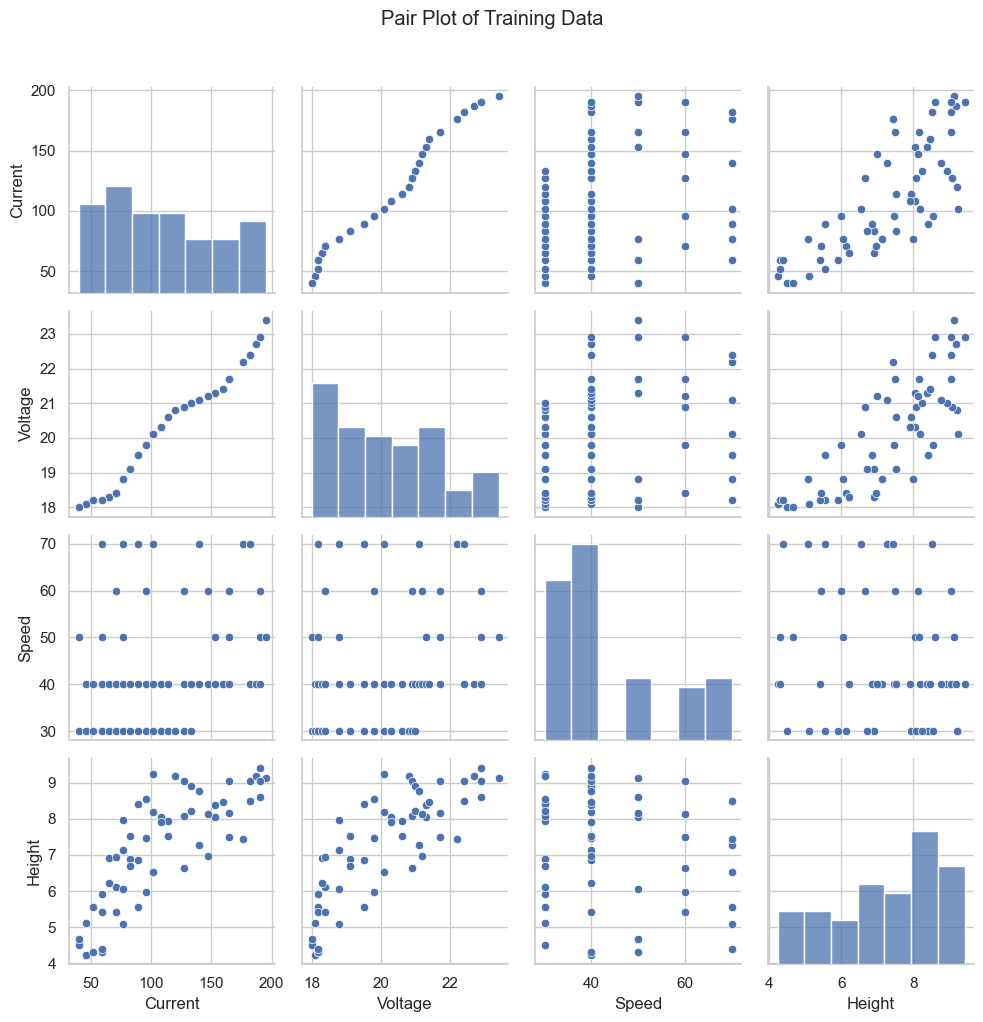

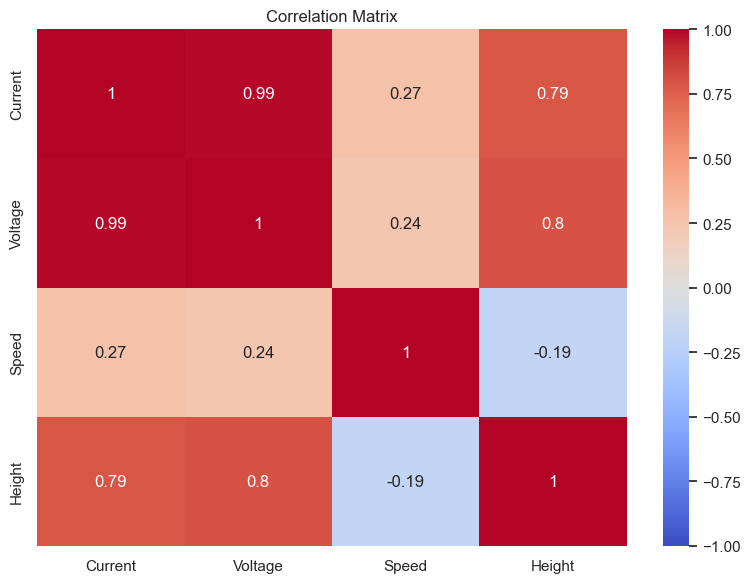

In [111]:
# Az adateloszlás vizualizálása
if len(df_train) > 0:
    # Diagram az összes változó közötti kapcsolat vizsgálatához
    sns.pairplot(df_train)
    plt.suptitle('Pair Plot of Training Data', y=1.02)
    plt.tight_layout()
    plt.show()
    
    # Korrelációs hőtérkép
    plt.figure(figsize=(8, 6))
    correlation = df_train.corr()
    sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Correlation Matrix')
    plt.tight_layout()
    plt.show()

## Lineáris Regressziós Modell

Egy lineáris regressziós modellt építünk a Magasság előrejelzésére az Áram, Feszültség és Sebesség alapján.

In [112]:
# Ellenőrizzük, hogy van-e elég adat a tanításhoz
if len(df_train) < 4:
    print("ERROR: Not enough data points with Height values for regression!")
else:
    # Jellemzők (X) és célérték (y) előkészítése
    X = df_train[['Current', 'Voltage', 'Speed']]
    y = df_train['Height']
    
    # Lineáris regressziós modell létrehozása
    model = LinearRegression()
    
    # Ellenőrizzük, hogy van-e elég adat a tanítás/teszt szétválasztáshoz
    if len(df_train) >= 10:
        # Az adatok felosztása tanítási és tesztelési halmazokra
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        print(f'Training set: {len(X_train)} minta')
        print(f'Testing set: {len(X_test)} minta')
    else:
        # Ha kevés adatunk van, használjuk az összeset tanításra és tesztelésre is
        print("Limited data available. Using all data for both training and evaluation.")
        X_train, X_test, y_train, y_test = X, X, y, y
    
    # Modell tanítása
    model.fit(X_train, y_train)
    
    # Modell együtthatók megjelenítése
    print('\nModel coefficients:')
    coef_df = pd.DataFrame({
        'Jellemző': X.columns,
        'Együttható': model.coef_
    })
    print(f"Intercept: {model.intercept_:.4f}")
    display(coef_df)
    
    # Képlet létrehozása
    formula = f"Height = {model.intercept_:.4f}"
    for i, feature in enumerate(X.columns):
        formula += f" + ({model.coef_[i]:.4f} × {feature})"
    
    print('\nRegression formula:')
    print(formula)

Training set: 48 minta
Testing set: 12 minta

Model coefficients:
Intercept: -4.7780


,Jellemző,Együttható
0,Current,0.007765
1,Voltage,0.671465
2,Speed,-0.052018



Regression formula:
Height = -4.7780 + (0.0078 × Current) + (0.6715 × Voltage) + (-0.0520 × Speed)


Modell teljesítménye:
Átlagos négyzetes hiba (MSE): 0.5824
Átlagos négyzetes hiba gyöke (RMSE): 0.7632
R² érték: 0.7295


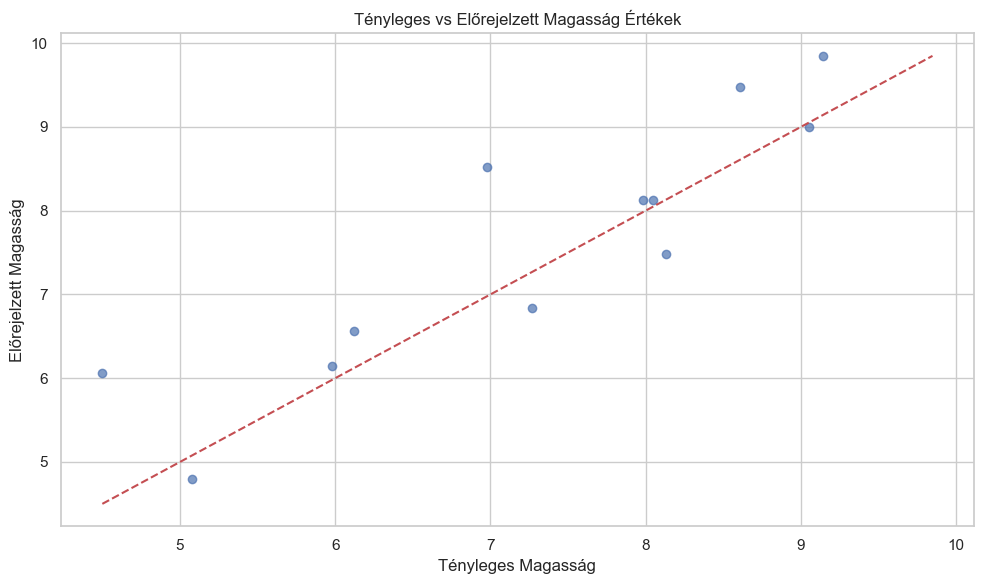

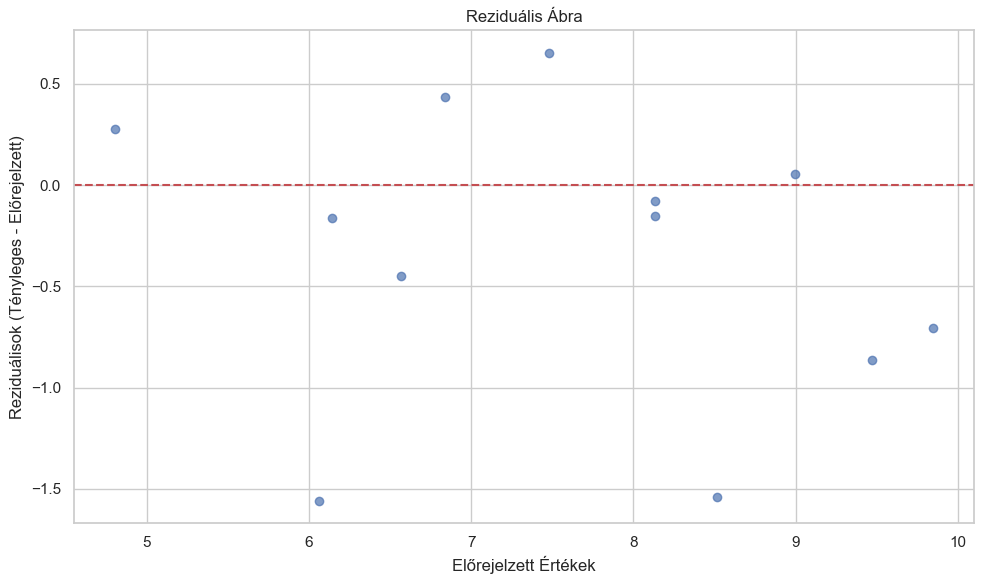

In [113]:
# A modell teljesítményének értékelése
if 'model' in locals() and len(df_train) >= 4:
    # Előrejelzések készítése a teszthalmazon
    y_pred = model.predict(X_test)
    
    # Értékelési metrikák kiszámítása
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    print('Modell teljesítménye:')
    print(f'Átlagos négyzetes hiba (MSE): {mse:.4f}')
    print(f'Átlagos négyzetes hiba gyöke (RMSE): {rmse:.4f}')
    print(f'R² érték: {r2:.4f}')
    
    # DataFrame létrehozása a tényleges és előrejelzett értékekkel
    results = pd.DataFrame({
        'Tényleges': y_test,
        'Előrejelzett': y_pred,
        'Különbség': y_test - y_pred
    })
    
    # Tényleges vs előrejelzett értékek vizualizálása
    plt.figure(figsize=(10, 6))
    plt.scatter(results['Tényleges'], results['Előrejelzett'], alpha=0.7)
    
    # Tökéletes előrejelzési vonal hozzáadása (y=x)
    min_val = min(results['Tényleges'].min(), results['Előrejelzett'].min())
    max_val = max(results['Tényleges'].max(), results['Előrejelzett'].max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--')
    
    plt.xlabel('Tényleges Magasság')
    plt.ylabel('Előrejelzett Magasság')
    plt.title('Tényleges vs Előrejelzett Magasság Értékek')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # Reziduális ábra
    plt.figure(figsize=(10, 6))
    plt.scatter(results['Előrejelzett'], results['Különbség'], alpha=0.7)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Előrejelzett Értékek')
    plt.ylabel('Reziduálisok (Tényleges - Előrejelzett)')
    plt.title('Reziduális Ábra')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Hiányzó magasság értékek előrejelzése

Most a modellünket fogjuk használni, hogy előrejelezzük a magasság értékeket azoknál a soroknál, ahol ezek hiányoznak.

In [ ]:
# Hiányzó magasság értékek előrejelzése
if 'model' in locals() and len(df_train) >= 4 and len(df_predict) > 0:
    # Jellemzők előkészítése az előrejelzéshez
    X_pred = df_predict[['Current', 'Voltage', 'Speed']]
    
    # Előrejelzések készítése
    height_predictions = model.predict(X_pred)
    
    # DataFrame létrehozása az előrejelzésekkel
    df_predictions = df_predict.copy()
    df_predictions['Előrejelzett_Magasság'] = height_predictions
    
    print(f'Előrejelzett magasság {len(df_predictions)} sorra:')
    display(df_predictions.head(10))
    
    # Teljes adatkészlet létrehozása mind a tényleges, mind az előrejelzett magasság értékekkel
    df_complete = df.copy()
    
    # Oszlop hozzáadása a magasság értékek forrásának jelölésére
    df_complete['Magasság_Forrás'] = 'Tényleges'
    
    # Hiányzó magasság értékek kitöltése előrejelzésekkel
    mask = df_complete['Height'].isna()
    df_complete.loc[mask, 'Height'] = model.predict(df_complete.loc[mask, ['Current', 'Voltage', 'Speed']])
    df_complete.loc[mask, 'Magasság_Forrás'] = 'Előrejelzett'
    
    print('\nTeljes adatkészlet tényleges és előrejelzett magasság értékekkel:')
    display(df_complete.head(10))
    
    # Teljes adatkészlet mentése Excel fájlba
    output_path = 'complete_data_with_predictions.xlsx'
    df_complete.to_excel(output_path, index=False)
    print(f'\nTeljes adatkészlet mentve: {output_path}')
elif len(df_predict) == 0:
    print('Nem található hiányzó magasság értékkel rendelkező sor - nincs mit előrejelezni.')
else:
    print('Nem lehet előrejelzéseket készíteni a nem elegendő tanítási adat miatt.')

Előrejelzett magasság 369 sorra:


,Current,Voltage,Speed,Height,Előrejelzett_Magasság
1,40,18.0,30,NaN,6.058431
2,40,18.0,30,NaN,6.058431
3,46,18.1,30,NaN,6.172165
5,46,18.1,30,NaN,6.172165
6,52,18.2,30,NaN,6.285899
8,52,18.2,30,NaN,6.285899
9,59,18.2,30,NaN,6.340251
11,59,18.2,30,NaN,6.340251
12,65,18.3,30,NaN,6.453985
14,65,18.3,30,NaN,6.453985



Teljes adatkészlet tényleges és előrejelzett magasság értékekkel:


,Current,Voltage,Speed,Height,Magasság_Forrás
0,40,18.0,30,4.500000,Tényleges
1,40,18.0,30,6.058431,Előrejelzett
2,40,18.0,30,6.058431,Előrejelzett
3,46,18.1,30,6.172165,Előrejelzett
4,46,18.1,30,5.100000,Tényleges
5,46,18.1,30,6.172165,Előrejelzett
6,52,18.2,30,6.285899,Előrejelzett
7,52,18.2,30,5.550000,Tényleges
8,52,18.2,30,6.285899,Előrejelzett
9,59,18.2,30,6.340251,Előrejelzett



Teljes adatkészlet mentve: d:/Users/Ainozu/Desktop/k/complete_data_with_predictions.xlsx


## Az előrejelzési eredmények elemzése

Elemezzük a tényleges és előrejelzett Magasság értékek eloszlását, hogy jobban megértsük a modellünket.

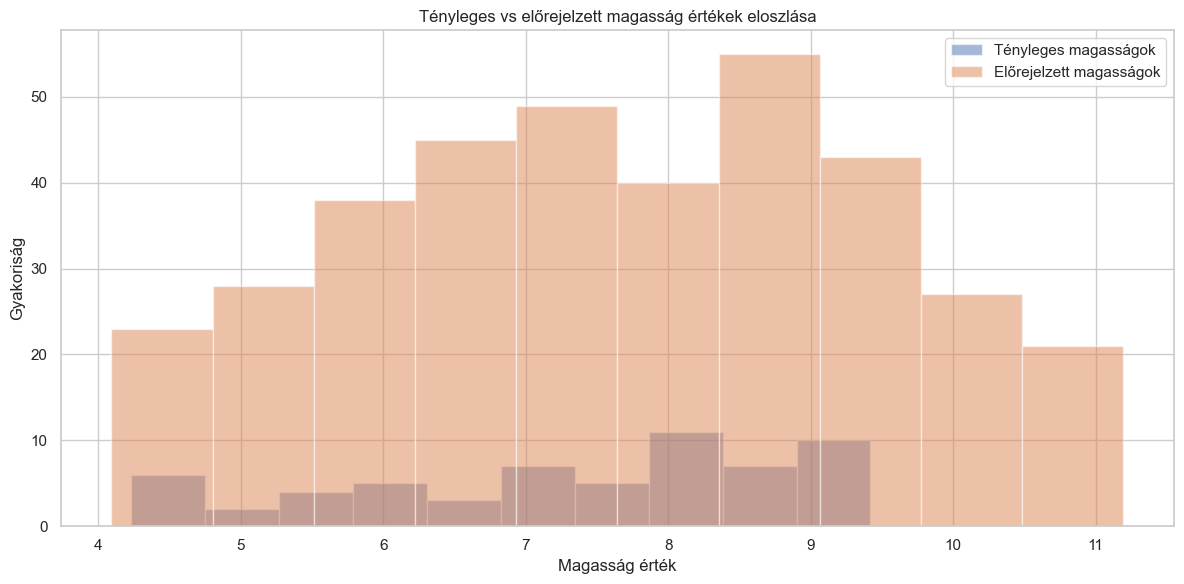

Összefoglaló statisztikák:


,Statisztika,Tényleges magasságok,Előrejelzett magasságok
0,Darabszám,60.000000,369.000000
1,Átlag,7.246667,7.652250
2,Medián,7.505000,7.701885
3,Minimum,4.230000,4.091433
4,Maximum,9.420000,11.195263
5,Szórás,1.509169,1.777075


In [115]:
# Tényleges és előrejelzett értékek eloszlásának elemzése
if 'df_complete' in locals() and len(df_complete) > 0:
    # Külön adatkészletek létrehozása a tényleges és előrejelzett értékekhez
    actual_heights = df_complete[df_complete['Magasság_Forrás'] == 'Tényleges']['Height']
    predicted_heights = df_complete[df_complete['Magasság_Forrás'] == 'Előrejelzett']['Height']
    
    # Eloszlások összehasonlítása, ha mindkettő rendelkezésre áll
    if len(actual_heights) > 0 and len(predicted_heights) > 0:
        plt.figure(figsize=(12, 6))
        
        # Hisztogramok ábrázolása
        plt.hist(actual_heights, alpha=0.5, label='Tényleges magasságok', bins=10)
        plt.hist(predicted_heights, alpha=0.5, label='Előrejelzett magasságok', bins=10)
        
        plt.xlabel('Magasság érték')
        plt.ylabel('Gyakoriság')
        plt.title('Tényleges vs előrejelzett magasság értékek eloszlása')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
        
        # Összefoglaló statisztikák
        print('Összefoglaló statisztikák:')
        stats_df = pd.DataFrame({
            'Statisztika': ['Darabszám', 'Átlag', 'Medián', 'Minimum', 'Maximum', 'Szórás'],
            'Tényleges magasságok': [len(actual_heights), actual_heights.mean(), actual_heights.median(), 
                                 actual_heights.min(), actual_heights.max(), actual_heights.std()],
            'Előrejelzett magasságok': [len(predicted_heights), predicted_heights.mean(), predicted_heights.median(), 
                                    predicted_heights.min(), predicted_heights.max(), predicted_heights.std()]
        })
        display(stats_df)

## Final Model Summary

A summary of our linear regression model and its application to the dataset.

In [116]:
# Végső modell összefoglaló
if 'model' in locals() and 'df_complete' in locals():
    print('Lineáris regressziós modell összefoglaló:')
    print('-' * 50)
    print(f'Modell képlete: {formula}')
    print('-' * 50)
    print(f'Teljes adathalmaz méret: {len(df)} sor')
    print(f'Sorok tényleges magasság értékekkel: {len(df_train)}')
    print(f'Sorok előrejelzett magasság értékekkel: {len(df_predict)}')
    print('-' * 50)
    if len(df_train) >= 10:
        print(f'Modell teljesítménye (R² érték): {r2:.4f}')
    else:
        print('Megjegyzés: Nem áll rendelkezésre elegendő adat a megbízható modell értékeléshez')
    print('-' * 50)
    print('Példa számítások:')
    
    # Példa számításokat néhány sorra
    if len(df_complete) > 0:
        sample = df_complete.sample(min(3, len(df_complete)))
        for _, row in sample.iterrows():
            calc = model.intercept_
            calc_str = f"{model.intercept_:.4f}"
            for i, feature in enumerate(['Current', 'Voltage', 'Speed']):
                term = model.coef_[i] * row[feature]
                calc += term
                calc_str += f" + ({model.coef_[i]:.4f} × {row[feature]:.2f})"
            calc_str += f" = {calc:.4f}"
            print(f"Áram={row['Current']:.2f}, Feszültség={row['Voltage']:.2f}, Sebesség={row['Speed']:.2f} esetén:")
            print(f"Magasság = {calc_str}")
            print()

Lineáris regressziós modell összefoglaló:
--------------------------------------------------
Modell képlete: Height = -4.7780 + (0.0078 × Current) + (0.6715 × Voltage) + (-0.0520 × Speed)
--------------------------------------------------
Teljes adathalmaz méret: 429 sor
Sorok tényleges magasság értékekkel: 60
Sorok előrejelzett magasság értékekkel: 369
--------------------------------------------------
Modell teljesítménye (R² érték): 0.7295
--------------------------------------------------
Példa számítások:
Áram=77.00, Feszültség=18.80, Sebesség=40.00 esetén:
Magasság = -4.7780 + (0.0078 × 77.00) + (0.6715 × 18.80) + (-0.0520 × 40.00) = 6.3627

Áram=40.00, Feszültség=18.00, Sebesség=40.00 esetén:
Magasság = -4.7780 + (0.0078 × 40.00) + (0.6715 × 18.00) + (-0.0520 × 40.00) = 5.5382

Áram=176.00, Feszültség=22.20, Sebesség=30.00 esetén:
Magasság = -4.7780 + (0.0078 × 176.00) + (0.6715 × 22.20) + (-0.0520 × 30.00) = 9.9346



| R² érték  | Értelmezés            |
|-----------|-----------------------|
| 0.0 - 0.3 | Gyenge magyarázóerő   |
| 0.3 - 0.5 | Közepes               |
| 0.5 - 0.7 | Jó                    |
| 0.7 - 0.9 | Nagyon jó             |
| 0.9 - 1.0 | Kiváló (de lehet túlillesztés is!) |